# Trade Shock Analysis — Suez Canal Blockage

This notebook examines how ARIMA and XGBoost forecasts behave around the March 2021 Suez Canal blockage. It produces historical one-month-ahead forecasts for January–June 2021: two pre-event months, the event month and three post-event months.

The models use trade-only inputs and the same historical cohort within each country. Each monthly fit uses preceding observations only. This is an exploratory forecast-response case study, not an event-prediction or causal attribution exercise. All outputs are saved under `results/suez/`.

## 1. Project Settings and Historical Window

Use the existing evaluation utility, ARIMA implementation settings from notebook 10, and saved XGBoost selection from notebook 11. No benchmark models or historical configuration searches are rerun. The cohort is fixed using December 2020 information, before the first target month.

Korean coverage starts in January 2019, allowing only 24 pre-2021 months. Apply a 24-month minimum history consistently across countries, at most 90% zero months, the existing adaptive top-partner rule, and a cap of 200 high-value series per country. This cap is for computation, not an exposure or representative-sampling criterion.

In [1]:
from pathlib import Path
import sys
import ast
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import duckdb
from statsmodels.tsa.arima.model import ARIMA
from xgboost import XGBRegressor
from bs4 import BeautifulSoup
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_loading import COUNTRY_PREFIXES, SERIES_KEYS, TARGET, DATA_DIR
from src.evaluation import evaluate_forecasts

RESULTS_DIR = PROJECT_ROOT / "results"
OUTPUT_DIR = RESULTS_DIR / "suez"
COHORT_CUTOFF = pd.Timestamp("2020-12-01")
FORECAST_MONTHS = pd.date_range("2021-01-01", "2021-06-01", freq="MS")
EVENT_MONTH = pd.Timestamp("2021-03-01")
MIN_HISTORY = 24
MAX_ZERO_SHARE = 0.90
TOP_N_PARTNERS = 20
PRODUCT_THRESHOLDS = [200, 150, 100, 50, 1]
MAX_SERIES = 200
RANDOM_SEED = 42
MODELS = ["ARIMA", "XGBoost"]
ID_COLUMNS = SERIES_KEYS + ["Month"]
COUNTRIES = list(COUNTRY_PREFIXES)
MODEL_COLORS = {"ARIMA": "#17becf", "XGBoost": "#ff7f0e"}
PROCESSED_FILES = {
    "South Korea": "korea_trade_monthly.parquet",
    "Slovakia": "slovakia_trade_monthly.parquet",
    "USA": "usa_trade_aggregated.parquet",
}
TRADE_FEATURES = [
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6", "rolling_mean_12",
    "rolling_std_3", "rolling_std_6", "rolling_std_12",
    "month_of_year", "month_sin", "month_cos",
]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "axes.axisbelow": True,
})
assert COHORT_CUTOFF < FORECAST_MONTHS.min()
assert MIN_HISTORY >= 13 and MAX_SERIES > 0

def event_period(month):
    month = pd.Timestamp(month)
    if month < EVENT_MONTH:
        return "Pre-event"
    if month == EVENT_MONTH:
        return "Event"
    return "Post-event"


## 2. Reuse Model Specifications

ARIMA(1,1,1) is the fixed specification already used in notebook 10; it was not selected through a configuration search. For XGBoost, read the existing dictionaries and saved February validation table from notebook 11 and verify the configuration recorded in the March result CSV.

XGBoost selection uses 2026 evidence, so its transfer to 2021 is retrospective. Historical fitting remains chronological, but this does not reproduce a configuration-selection decision available in 2021. REER and LSTM are not included.

In [2]:
def read_notebook_setting(notebook_name, variable_name):
    notebook = json.loads(
        (PROJECT_ROOT / "notebooks" / notebook_name).read_text(encoding="utf-8")
    )
    for cell in notebook["cells"]:
        if cell["cell_type"] == "code":
            for node in ast.walk(ast.parse("".join(cell["source"]))):
                if isinstance(node, ast.Assign):
                    if any(isinstance(item, ast.Name) and item.id == variable_name
                           for item in node.targets):
                        return ast.literal_eval(node.value)
    raise ValueError(f"{variable_name} was not found in {notebook_name}.")


def read_validation_table(notebook_name, required_columns):
    notebook = json.loads(
        (PROJECT_ROOT / "notebooks" / notebook_name).read_text(encoding="utf-8")
    )
    for cell in notebook["cells"]:
        for output in cell.get("outputs", []):
            html = "".join(output.get("data", {}).get("text/html", []))
            for table in BeautifulSoup(html, "html.parser").find_all("table"):
                columns = [item.get_text(strip=True) for item in table.select("thead th")]
                columns = [name for name in columns if name]
                if set(required_columns).issubset(columns):
                    rows = [
                        [item.get_text(strip=True) for item in row.find_all("td")]
                        for row in table.select("tbody tr")
                    ]
                    return pd.DataFrame(rows, columns=columns)
    raise ValueError(f"Save {notebook_name} with its validation table outputs first.")


XGBOOST_CONFIGS = read_notebook_setting(
    "11_machine_learning_models.ipynb", "XGBOOST_CONFIGS"
)
xgb_validation = read_validation_table(
    "11_machine_learning_models.ipynb",
    ["Country", "Configuration", "Validation Month", "MAE"],
)
xgb_validation["MAE"] = pd.to_numeric(xgb_validation["MAE"], errors="raise")
assert xgb_validation["Validation Month"].eq("2026-02").all()
assert not xgb_validation.duplicated(["Country", "Configuration"]).any()

saved_xgb = pd.read_csv(RESULTS_DIR / "xgboost_results.csv")
saved_arima = pd.read_csv(RESULTS_DIR / "arima_results.csv")
for table in [saved_xgb, saved_arima]:
    assert not table.Country.duplicated().any()
    assert set(table.Country) == set(COUNTRIES)
    assert table["Forecast Month"].eq("2026-03").all()

model_settings = {}
setting_rows = []
for country in COUNTRIES:
    label = saved_xgb.loc[saved_xgb.Country.eq(country), "Model"].iloc[0]
    config_name = str(label).split("(")[-1].rstrip(")")
    country_validation = xgb_validation.loc[xgb_validation.Country.eq(country)]
    assert set(country_validation.Configuration) == set(XGBOOST_CONFIGS)
    selected = country_validation.sort_values("MAE", kind="stable").iloc[0].Configuration
    assert config_name == selected

    arima_label = saved_arima.loc[saved_arima.Country.eq(country), "Model"].iloc[0]
    assert arima_label == "ARIMA(1,1,1)", "Check notebook 10 before changing the ARIMA order."
    model_settings[(country, "ARIMA")] = {
        "Configuration": arima_label, "Parameters": {"order": (1, 1, 1)},
    }
    model_settings[(country, "XGBoost")] = {
        "Configuration": config_name, "Parameters": XGBOOST_CONFIGS[config_name],
    }
    for model in MODELS:
        setting_rows.append({
            "Country": country, "Model": model, **model_settings[(country, model)],
        })
display(pd.DataFrame(setting_rows))

,Country,Model,Configuration,Parameters
0,South Korea,ARIMA,"ARIMA(1,1,1)","{'order': (1, 1, 1)}"
1,South Korea,XGBoost,XGBoost_3,"{'n_estimators': 300, 'max_depth': 8, 'learnin..."
2,Slovakia,ARIMA,"ARIMA(1,1,1)","{'order': (1, 1, 1)}"
3,Slovakia,XGBoost,XGBoost_1,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
4,USA,ARIMA,"ARIMA(1,1,1)","{'order': (1, 1, 1)}"
5,USA,XGBoost,XGBoost_3,"{'n_estimators': 300, 'max_depth': 8, 'learnin..."


## 3. Historical Coverage and Cohort Selection

Read the harmonized processed datasets rather than the March-2026-selected panels. Compute history length, zero share and partner rankings using December 2020 and earlier only. Missing months count as zero from each series' first observation to the cutoff. After applying the partner rule, retain at most 200 series by pre-cutoff trade value and freeze them for all six targets.

Complete the selected series through June 2021 using zero for absent monthly observations. Source-observation flags distinguish those zeros from recorded values. Country-level months must be present, but that check alone cannot prove extract completeness. Changes in reporting coverage, especially the sparser USA observations in early 2021, may influence forecast errors.

In [3]:
def prepare_historical_panel(country):
    path = DATA_DIR / "processed" / PROCESSED_FILES[country]
    if not path.is_file():
        raise FileNotFoundError(path)
    keys = ", ".join(SERIES_KEYS)
    with duckdb.connect() as con:
        con.execute("SET enable_progress_bar=false")
        source_coverage = con.execute(
            """SELECT Month, COUNT(*) AS SourceRows, SUM(Value) AS SourceTotalValue
               FROM read_parquet(?)
               WHERE Month BETWEEN ?::DATE AND ?::DATE
               GROUP BY Month ORDER BY Month""",
            [str(path), COHORT_CUTOFF.to_pydatetime(), FORECAST_MONTHS.max().to_pydatetime()],
        ).df()
        available = set(pd.to_datetime(source_coverage.Month))
        assert set(FORECAST_MONTHS).issubset(available), (
            f"{country}: incomplete country-level coverage for the target window."
        )
        summary = con.execute(
            f"""SELECT {keys}, MIN(Month) AS FirstMonth,
                MAX(Month) AS LastPreEventObservation,
                SUM(Value) AS HistoricalTrade,
                COUNT(*) FILTER (WHERE Value > 0) AS PositiveMonths,
                date_diff('month', MIN(Month), ?::DATE) + 1 AS HistoryMonths
                FROM read_parquet(?)
                WHERE Month <= ?::DATE GROUP BY {keys}""",
            [COHORT_CUTOFF.to_pydatetime(), str(path), COHORT_CUTOFF.to_pydatetime()],
        ).df()
        summary["ZeroShare"] = 1 - summary.PositiveMonths / summary.HistoryMonths
        eligible = summary.loc[
            summary.HistoryMonths.ge(MIN_HISTORY)
            & summary.ZeroShare.le(MAX_ZERO_SHARE)
        ].copy()
        partners = eligible.groupby("Country2", observed=True).agg(
            HistoricalTrade=("HistoricalTrade", "sum"),
            Products=("ProductCode", "nunique"),
        ).sort_values("HistoricalTrade", ascending=False, kind="stable")
        for threshold in PRODUCT_THRESHOLDS:
            qualifying = partners.loc[partners.Products.ge(threshold)]
            if len(qualifying) >= TOP_N_PARTNERS:
                break
        selected_partners = qualifying.head(TOP_N_PARTNERS).index
        cohort = eligible.loc[eligible.Country2.isin(selected_partners)].sort_values(
            ["HistoricalTrade"] + SERIES_KEYS,
            ascending=[False] + [True] * len(SERIES_KEYS),
            kind="stable",
        ).head(MAX_SERIES).reset_index(drop=True)
        if cohort.empty:
            raise ValueError(f"{country}: no eligible historical series.")
        cohort["Country"] = country
        cohort["CohortCutoff"] = COHORT_CUTOFF
        cohort["ProductThreshold"] = threshold
        con.register("selected_cohort", cohort)
        panel = con.execute(
            """SELECT c.Country1, c.Country2, c.ProductCode, c.TradeFlow,
                      m.Month, COALESCE(d.Value, 0.0) AS Value,
                      (d.Month IS NOT NULL) AS SourceObserved
               FROM selected_cohort c
               CROSS JOIN LATERAL generate_series(
                   c.FirstMonth::TIMESTAMP, ?::TIMESTAMP, INTERVAL 1 MONTH
               ) m(Month)
               LEFT JOIN read_parquet(?) d
                 ON d.Country1=c.Country1 AND d.Country2=c.Country2
                AND d.ProductCode=c.ProductCode AND d.TradeFlow=c.TradeFlow
                AND d.Month=m.Month
               ORDER BY c.Country1, c.Country2, c.ProductCode, c.TradeFlow, m.Month""",
            [FORECAST_MONTHS.max().to_pydatetime(), str(path)],
        ).df()
    panel["Month"] = pd.to_datetime(panel.Month)
    assert not panel.duplicated(ID_COLUMNS).any()
    assert panel[SERIES_KEYS + [TARGET]].notna().all().all()
    assert panel[TARGET].ge(0).all() and np.isfinite(panel[TARGET]).all()
    assert cohort.HistoryMonths.ge(MIN_HISTORY).all()
    assert cohort.ZeroShare.le(MAX_ZERO_SHARE).all()
    assert cohort.LastPreEventObservation.le(COHORT_CUTOFF).all()
    source_coverage["Country"] = country
    source_coverage["SourceFile"] = path.name
    return panel, cohort, source_coverage


historical_data = {}
cohort_tables = []
coverage_tables = []
cohort_summary = []
for country in COUNTRIES:
    panel, cohort, coverage = prepare_historical_panel(country)
    historical_data[country] = panel
    cohort_tables.append(cohort)
    coverage_tables.append(coverage)
    cohort_summary.append({
        "Country": country, "N Series": len(cohort),
        "Partners after cap": cohort.Country2.nunique(),
        "Earliest month": panel.Month.min(),
        "Minimum history at cutoff": int(cohort.HistoryMonths.min()),
        "Maximum pre-cutoff zero share": float(cohort.ZeroShare.max()),
    })
cohort_table = pd.concat(cohort_tables, ignore_index=True)
coverage_table = pd.concat(coverage_tables, ignore_index=True)
display(pd.DataFrame(cohort_summary))
display(coverage_table)

,Country,N Series,Partners after cap,Earliest month,Minimum history at cutoff,Maximum pre-cutoff zero share
0,South Korea,200,19,2019-01-01,24,0.166667
1,Slovakia,200,20,2015-01-01,71,0.112676
2,USA,200,20,2017-01-01,47,0.145833


,Month,SourceRows,SourceTotalValue,Country,SourceFile
0,2020-12-01,85876,9.594530e+10,South Korea,korea_trade_monthly.parquet
1,2021-01-01,82974,9.224847e+10,South Korea,korea_trade_monthly.parquet
2,2021-02-01,82308,8.697859e+10,South Korea,korea_trade_monthly.parquet
3,2021-03-01,87974,1.034129e+11,South Korea,korea_trade_monthly.parquet
4,2021-04-01,85870,1.019418e+11,South Korea,korea_trade_monthly.parquet
5,2021-05-01,83834,9.852117e+10,South Korea,korea_trade_monthly.parquet
6,2021-06-01,86258,1.051369e+11,South Korea,korea_trade_monthly.parquet
7,2020-12-01,34997,1.271231e+10,Slovakia,slovakia_trade_monthly.parquet
8,2021-01-01,34392,1.265482e+10,Slovakia,slovakia_trade_monthly.parquet
9,2021-02-01,35608,1.388630e+10,Slovakia,slovakia_trade_monthly.parquet


## 4. Historical Trade Features

Construct the same lag, shifted rolling and calendar features as notebooks 07 and 11. These features are computed on the completed monthly panel and use earlier values only. Each monthly training set is subsequently restricted to dates before its target, so the later observed values enter only later forecast origins.

The selected cohort is checked for continuous monthly histories and exactly one target row per series in every evaluation month. No historical feature datasets are written to disk.

In [4]:
def add_historical_features(df):
    df = df.sort_values(SERIES_KEYS + ["Month"]).reset_index(drop=True).copy()
    values = df.groupby(SERIES_KEYS, sort=False, observed=True)[TARGET]
    for lag in [1, 2, 3, 6, 12]:
        df[f"lag_{lag}"] = values.shift(lag)
    for window in [3, 6, 12]:
        df[f"rolling_mean_{window}"] = values.transform(
            lambda series: series.shift(1).rolling(window, min_periods=window).mean()
        )
        df[f"rolling_std_{window}"] = values.transform(
            lambda series: series.shift(1).rolling(window, min_periods=window).std()
        )
    month = df.Month.dt.month
    df["month_of_year"] = month.astype("int8")
    df["month_sin"] = np.sin(2 * np.pi * month / 12).astype("float32")
    df["month_cos"] = np.cos(2 * np.pi * month / 12).astype("float32")
    return df


expected_target_rows = []
for country in COUNTRIES:
    panel = add_historical_features(historical_data[country])
    periods = panel.Month.dt.year * 12 + panel.Month.dt.month
    assert periods.groupby(
        [panel[key] for key in SERIES_KEYS], observed=True
    ).diff().dropna().eq(1).all()
    cohort_keys = panel[SERIES_KEYS].drop_duplicates().sort_values(
        SERIES_KEYS
    ).reset_index(drop=True)
    for month in FORECAST_MONTHS:
        target = panel.loc[panel.Month.eq(month)]
        actual_keys = target[SERIES_KEYS].sort_values(SERIES_KEYS).reset_index(drop=True)
        pd.testing.assert_frame_equal(actual_keys, cohort_keys)
        assert target[TRADE_FEATURES].notna().all().all()
        previous = panel.loc[panel.Month.eq(month - pd.DateOffset(months=1))]
        previous = previous.set_index(SERIES_KEYS)[TARGET]
        lagged = target.set_index(SERIES_KEYS).lag_1
        np.testing.assert_allclose(lagged.sort_index(), previous.sort_index())
        expected = target[ID_COLUMNS + [TARGET, "SourceObserved"]].copy()
        expected["Country"] = country
        for model in MODELS:
            rows = expected.copy()
            rows["Model"] = model
            expected_target_rows.append(rows)
    historical_data[country] = panel

expected_targets = pd.concat(expected_target_rows, ignore_index=True)
print("Fixed historical target observations:", len(expected_targets))

Fixed historical target observations: 7200


## 5. Historical Model Fitting

ARIMA follows notebook 10's raw target and order (1,1,1), with stationarity and invertibility enforcement disabled. Its native forecasts remain unconstrained; negative forecasts are recorded. XGBoost follows notebook 11's pooled country model, native handling of initial missing lag features, and non-negative predictions.

For this matched historical comparison, handled ARIMA errors, non-convergence and non-finite forecasts use the latest historical trade value as a recorded naive fallback. Unlike notebook 10's excluded failed fits, no series is removed here. Fallback counts must therefore accompany ARIMA interpretation. A pooled XGBoost failure stops the experiment rather than silently excluding observations.

In [5]:
def forecast_arima(history, target, country, month, params):
    lookup = {
        key: group.sort_values("Month")
        for key, group in history.groupby(SERIES_KEYS, sort=False, observed=True)
    }
    predictions, fallbacks, diagnostics = [], [], []
    for key in target[SERIES_KEYS].itertuples(index=False, name=None):
        group = lookup[key]
        assert group.Month.iloc[-1] == month - pd.DateOffset(months=1)
        y = group[TARGET].to_numpy(dtype=float)
        assert np.isfinite(y).all()
        prediction, fallback = float(y[-1]), False
        common = {
            "Country": country, "Model": "ARIMA",
            "Forecast Month": month.strftime("%Y-%m"),
            **dict(zip(SERIES_KEYS, key)),
        }
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            try:
                fitted = ARIMA(
                    y, order=tuple(params["order"]),
                    enforce_stationarity=False, enforce_invertibility=False,
                ).fit()
                prediction = float(fitted.forecast(steps=1)[0])
                if not fitted.mle_retvals.get("converged", True):
                    raise ValueError("ARIMA fit did not converge.")
                if not np.isfinite(prediction):
                    raise ValueError("Non-finite ARIMA forecast.")
            except (ValueError, np.linalg.LinAlgError, RuntimeError,
                    FloatingPointError, OverflowError) as exc:
                prediction, fallback = float(y[-1]), True
                diagnostics.append({**common, "Action": "naive_fallback", "Message": str(exc)})
        for warning in caught:
            diagnostics.append({
                **common, "Action": "warning", "Message": str(warning.message),
            })
        if prediction < 0:
            diagnostics.append({
                **common, "Action": "negative_forecast",
                "Message": "Native ARIMA forecast is negative; retained as in notebook 10.",
            })
        predictions.append(prediction)
        fallbacks.append(fallback)
    return np.asarray(predictions), np.asarray(fallbacks), diagnostics


def forecast_xgboost(history, target, params):
    model = XGBRegressor(
        **params, objective="reg:squarederror", tree_method="hist",
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=RANDOM_SEED, n_jobs=-1,
    )
    model.fit(history[TRADE_FEATURES], history[TARGET])
    predictions = np.maximum(model.predict(target[TRADE_FEATURES]), 0.0)
    return predictions, np.zeros(len(target), dtype=bool), []

## 6. January June Out-of-Sample Forecasts

Refit the selected specification at each monthly origin and predict the next month. January uses data through December 2020; June uses data through May 2021. These are sequential one-step forecasts, not a six-step forecast made in December.

Individual predictions and fitting diagnostics remain in memory for evaluation and display. Every fresh run refits the historical models. Only monthly_results.csv, period_results.csv, actual_vs_forecast.png and monthly_errors.png are saved under results/suez/. The original March benchmarks and prepared datasets are preserved.


In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
diagnostic_columns = [
    "Country", "Model", "Forecast Month", *SERIES_KEYS, "Action", "Message"
]
prediction_frames, diagnostic_rows = [], []
for country in COUNTRIES:
    panel = historical_data[country]
    for model in MODELS:
        setting = model_settings[(country, model)]
        for month in FORECAST_MONTHS:
            history = panel.loc[panel.Month < month]
            target = panel.loc[panel.Month.eq(month)].reset_index(drop=True)
            assert history.Month.max() == month - pd.DateOffset(months=1)
            if model == "ARIMA":
                predicted, fallback, issues = forecast_arima(
                    history, target, country, month, setting["Parameters"]
                )
            else:
                predicted, fallback, issues = forecast_xgboost(
                    history, target, setting["Parameters"]
                )
            assert len(predicted) == len(target) and np.isfinite(predicted).all()
            frame = target[ID_COLUMNS + [TARGET, "SourceObserved"]].copy()
            frame["Country"] = country
            frame["Model"] = model
            frame["Configuration"] = setting["Configuration"]
            frame["Parameters"] = repr(setting["Parameters"])
            frame["Forecast Origin"] = str((month - pd.Timedelta(days=1)).date())
            frame["CohortCutoff"] = COHORT_CUTOFF
            frame["Prediction"] = predicted
            frame["Residual"] = frame[TARGET] - frame.Prediction
            frame["Fallback"] = fallback
            prediction_frames.append(frame)
            diagnostic_rows.extend(issues)
            print(
                f"{country}, {model}, {month:%Y-%m}: {len(target)} forecasts; "
                f"{int(fallback.sum())} naive fallbacks."
            )
predictions = pd.concat(prediction_frames, ignore_index=True)
diagnostics = pd.DataFrame(diagnostic_rows, columns=diagnostic_columns)
assert not predictions.duplicated(["Country", "Model"] + ID_COLUMNS).any()
predictions["Residual"] = predictions[TARGET] - predictions.Prediction
predictions["Period"] = predictions.Month.map(event_period)
print("Historical forecasts available in memory:", len(predictions))


South Korea, ARIMA, 2021-01: 200 forecasts; 8 naive fallbacks.
South Korea, ARIMA, 2021-02: 200 forecasts; 10 naive fallbacks.
South Korea, ARIMA, 2021-03: 200 forecasts; 8 naive fallbacks.
South Korea, ARIMA, 2021-04: 200 forecasts; 10 naive fallbacks.
South Korea, ARIMA, 2021-05: 200 forecasts; 5 naive fallbacks.
South Korea, ARIMA, 2021-06: 200 forecasts; 5 naive fallbacks.
South Korea, XGBoost, 2021-01: 200 forecasts; 0 naive fallbacks.
South Korea, XGBoost, 2021-02: 200 forecasts; 0 naive fallbacks.
South Korea, XGBoost, 2021-03: 200 forecasts; 0 naive fallbacks.
South Korea, XGBoost, 2021-04: 200 forecasts; 0 naive fallbacks.
South Korea, XGBoost, 2021-05: 200 forecasts; 0 naive fallbacks.
South Korea, XGBoost, 2021-06: 200 forecasts; 0 naive fallbacks.
Slovakia, ARIMA, 2021-01: 200 forecasts; 11 naive fallbacks.
Slovakia, ARIMA, 2021-02: 200 forecasts; 11 naive fallbacks.
Slovakia, ARIMA, 2021-03: 200 forecasts; 14 naive fallbacks.
Slovakia, ARIMA, 2021-04: 200 forecasts; 6 naiv

## 7. Monthly and Pre/Event/Post Evaluation

Calculate MAE, RMSE and sMAPE on the same series for every month and model, including zero-completed targets. Record fallback counts, negative forecasts and the number of targets absent from the source. These are diagnostics, not exclusions.

Period scores pool the underlying observations: two months before, one event month and three months after. Pooled RMSE is calculated from errors rather than averaging monthly RMSE values. Period tables distinguish unique series, observations and months. Error changes are measured against the January–February reference; relative changes are undefined when its error is zero.

In [7]:
monthly_rows = []
for (country, model, month), group in predictions.groupby(["Country", "Model", "Month"]):
    row = evaluate_forecasts(
        country, model, group[TARGET], group.Prediction, month.strftime("%Y-%m")
    )
    row.update({
        "Period": event_period(month),
        "Forecast Origin": str((month - pd.Timedelta(days=1)).date()),
        "Configuration": group.Configuration.iloc[0],
        "Naive fallbacks": int(group.Fallback.sum()),
        "Negative forecasts": int(group.Prediction.lt(0).sum()),
        "Zero actuals": int(group[TARGET].eq(0).sum()),
        "Zero-completed targets": int((~group.SourceObserved).sum()),
    })
    monthly_rows.append(row)
monthly_results = pd.DataFrame(monthly_rows)

period_rows = []
for (country, model, period), group in predictions.groupby(["Country", "Model", "Period"]):
    row = evaluate_forecasts(country, model, group[TARGET], group.Prediction, "2021-01 to 2021-06")
    row["N Observations"] = row.pop("N Series")
    row.update({
        "Period": period,
        "Configuration": group.Configuration.iloc[0],
        "N Series": len(group[SERIES_KEYS].drop_duplicates()),
        "N Months": group.Month.nunique(),
        "Naive fallbacks": int(group.Fallback.sum()),
        "Negative forecasts": int(group.Prediction.lt(0).sum()),
        "Zero-completed targets": int((~group.SourceObserved).sum()),
    })
    period_rows.append(row)
period_results = pd.DataFrame(period_rows)
pre_reference = period_results.loc[
    period_results.Period.eq("Pre-event"),
    ["Country", "Model", "MAE", "RMSE", "sMAPE (%)"],
].rename(columns={
    "MAE": "Pre-event MAE", "RMSE": "Pre-event RMSE",
    "sMAPE (%)": "Pre-event sMAPE (%)",
})

monthly_results = monthly_results.merge(
    pre_reference, on=["Country", "Model"], validate="many_to_one"
)
period_results = period_results.merge(
    pre_reference, on=["Country", "Model"], validate="many_to_one"
)
for table in [monthly_results, period_results]:
    for metric, baseline, difference, percentage in [
        ("MAE", "Pre-event MAE", "MAE difference", "MAE change (%)"),
        ("RMSE", "Pre-event RMSE", "RMSE difference", "RMSE change (%)"),
        ("sMAPE (%)", "Pre-event sMAPE (%)", "sMAPE difference (pp)", "sMAPE change (%)"),
    ]:
        table[difference] = table[metric] - table[baseline]
        table[percentage] = 100 * table[difference] / table[baseline].replace(0, np.nan)

monthly_results = monthly_results.sort_values(["Country", "Model", "Forecast Month"])
period_order = {"Pre-event": 0, "Event": 1, "Post-event": 2}
period_results = period_results.assign(
    PeriodOrder=period_results.Period.map(period_order)
).sort_values(["Country", "Model", "PeriodOrder"]).drop(columns="PeriodOrder")
assert len(monthly_results) == len(COUNTRIES) * len(MODELS) * len(FORECAST_MONTHS)
assert len(period_results) == len(COUNTRIES) * len(MODELS) * 3
assert monthly_results.groupby("Country")["N Series"].nunique().eq(1).all()
assert period_results["N Observations"].eq(
    period_results["N Series"] * period_results["N Months"]
).all()

monthly_results.to_csv(OUTPUT_DIR / "monthly_results.csv", index=False)
period_results.to_csv(OUTPUT_DIR / "period_results.csv", index=False)
display(monthly_results)
display(period_results)
print("Recorded fitting diagnostics:", len(diagnostics))
display(diagnostics)

,Country,Model,Forecast Month,N Series,MAE,RMSE,sMAPE (%),Period,Forecast Origin,Configuration,...,Zero-completed targets,Pre-event MAE,Pre-event RMSE,Pre-event sMAPE (%),MAE difference,MAE change (%),RMSE difference,RMSE change (%),sMAPE difference (pp),sMAPE change (%)
0,Slovakia,ARIMA,2021-01,200,5.733026e+06,1.255060e+07,26.751341,Pre-event,2020-12-31,"ARIMA(1,1,1)",...,1,5.474196e+06,1.201702e+07,23.901188,2.588301e+05,4.728184,5.335794e+05,4.440198,2.850153,11.924732
1,Slovakia,ARIMA,2021-02,200,5.215366e+06,1.145862e+07,21.051035,Pre-event,2021-01-31,"ARIMA(1,1,1)",...,1,5.474196e+06,1.201702e+07,23.901188,-2.588301e+05,-4.728184,-5.583991e+05,-4.646735,-2.850153,-11.924732
2,Slovakia,ARIMA,2021-03,200,7.193018e+06,1.564230e+07,23.634439,Event,2021-02-28,"ARIMA(1,1,1)",...,1,5.474196e+06,1.201702e+07,23.901188,1.718822e+06,31.398617,3.625277e+06,30.167858,-0.266749,-1.116050
3,Slovakia,ARIMA,2021-04,200,4.875243e+06,1.318293e+07,19.079614,Post-event,2021-03-31,"ARIMA(1,1,1)",...,1,5.474196e+06,1.201702e+07,23.901188,-5.989529e+05,-10.941386,1.165913e+06,9.702178,-4.821574,-20.172948
4,Slovakia,ARIMA,2021-05,200,6.015969e+06,1.420967e+07,24.663024,Post-event,2021-04-30,"ARIMA(1,1,1)",...,1,5.474196e+06,1.201702e+07,23.901188,5.417728e+05,9.896847,2.192655e+06,18.246246,0.761836,3.187438
5,Slovakia,ARIMA,2021-06,200,5.936756e+06,1.422553e+07,20.546695,Post-event,2021-05-31,"ARIMA(1,1,1)",...,2,5.474196e+06,1.201702e+07,23.901188,4.625597e+05,8.449819,2.208516e+06,18.378231,-3.354493,-14.034839
6,Slovakia,XGBoost,2021-01,200,5.995948e+06,1.215339e+07,28.752456,Pre-event,2020-12-31,XGBoost_1,...,1,5.833386e+06,1.475858e+07,25.384000,1.625615e+05,2.786744,-2.605191e+06,-17.652045,3.368457,13.269999
7,Slovakia,XGBoost,2021-02,200,5.670825e+06,1.696839e+07,22.015543,Pre-event,2021-01-31,XGBoost_1,...,1,5.833386e+06,1.475858e+07,25.384000,-1.625615e+05,-2.786744,2.209817e+06,14.973103,-3.368457,-13.269999
8,Slovakia,XGBoost,2021-03,200,7.547744e+06,1.534428e+07,24.901546,Event,2021-02-28,XGBoost_1,...,1,5.833386e+06,1.475858e+07,25.384000,1.714358e+06,29.388723,5.857002e+05,3.968542,-0.482454,-1.900623
9,Slovakia,XGBoost,2021-04,200,6.421277e+06,2.080836e+07,21.049715,Post-event,2021-03-31,XGBoost_1,...,1,5.833386e+06,1.475858e+07,25.384000,5.878909e+05,10.078037,6.049782e+06,40.991637,-4.334285,-17.074870


,Country,Model,Forecast Month,MAE,RMSE,sMAPE (%),N Observations,Period,Configuration,N Series,...,Zero-completed targets,Pre-event MAE,Pre-event RMSE,Pre-event sMAPE (%),MAE difference,MAE change (%),RMSE difference,RMSE change (%),sMAPE difference (pp),sMAPE change (%)
2,Slovakia,ARIMA,2021-01 to 2021-06,5.474196e+06,1.201702e+07,23.901188,400,Pre-event,"ARIMA(1,1,1)",200,...,2,5.474196e+06,1.201702e+07,23.901188,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000
0,Slovakia,ARIMA,2021-01 to 2021-06,7.193018e+06,1.564230e+07,23.634439,200,Event,"ARIMA(1,1,1)",200,...,1,5.474196e+06,1.201702e+07,23.901188,1.718822e+06,31.398617,3.625277e+06,30.167858,-0.266749,-1.116050
1,Slovakia,ARIMA,2021-01 to 2021-06,5.609322e+06,1.388129e+07,21.429777,600,Post-event,"ARIMA(1,1,1)",200,...,4,5.474196e+06,1.201702e+07,23.901188,1.351265e+05,2.468426,1.864268e+06,15.513561,-2.471411,-10.340116
5,Slovakia,XGBoost,2021-01 to 2021-06,5.833386e+06,1.475858e+07,25.384000,400,Pre-event,XGBoost_1,200,...,2,5.833386e+06,1.475858e+07,25.384000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000
3,Slovakia,XGBoost,2021-01 to 2021-06,7.547744e+06,1.534428e+07,24.901546,200,Event,XGBoost_1,200,...,1,5.833386e+06,1.475858e+07,25.384000,1.714358e+06,29.388723,5.857002e+05,3.968542,-0.482454,-1.900623
4,Slovakia,XGBoost,2021-01 to 2021-06,6.191136e+06,1.789181e+07,22.945262,600,Post-event,XGBoost_1,200,...,4,5.833386e+06,1.475858e+07,25.384000,3.577499e+05,6.132800,3.133233e+06,21.229916,-2.438738,-9.607383
8,South Korea,ARIMA,2021-01 to 2021-06,3.855386e+07,7.601939e+07,25.297110,400,Pre-event,"ARIMA(1,1,1)",200,...,0,3.855386e+07,7.601939e+07,25.297110,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000
6,South Korea,ARIMA,2021-01 to 2021-06,5.127042e+07,9.691139e+07,28.462547,200,Event,"ARIMA(1,1,1)",200,...,0,3.855386e+07,7.601939e+07,25.297110,1.271656e+07,32.983887,2.089200e+07,27.482465,3.165437,12.513038
7,South Korea,ARIMA,2021-01 to 2021-06,4.115034e+07,8.195492e+07,22.913566,600,Post-event,"ARIMA(1,1,1)",200,...,2,3.855386e+07,7.601939e+07,25.297110,2.596477e+06,6.734676,5.935536e+06,7.807924,-2.383545,-9.422202
11,South Korea,XGBoost,2021-01 to 2021-06,3.948435e+07,7.723557e+07,25.344879,400,Pre-event,XGBoost_3,200,...,0,3.948435e+07,7.723557e+07,25.344879,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000


Recorded fitting diagnostics: 325


,Country,Model,Forecast Month,Country1,Country2,ProductCode,TradeFlow,Action,Message
0,South Korea,ARIMA,2021-01,KOR,can,8703,export,naive_fallback,ARIMA fit did not converge.
1,South Korea,ARIMA,2021-01,KOR,can,8703,export,warning,Maximum Likelihood optimization failed to conv...
2,South Korea,ARIMA,2021-01,KOR,chn,7403,export,naive_fallback,ARIMA fit did not converge.
3,South Korea,ARIMA,2021-01,KOR,chn,7403,export,warning,Maximum Likelihood optimization failed to conv...
4,South Korea,ARIMA,2021-01,KOR,chn,8414,import,naive_fallback,ARIMA fit did not converge.
...,...,...,...,...,...,...,...,...,...
320,USA,ARIMA,2021-06,USA,mex,8536,import,warning,Maximum Likelihood optimization failed to conv...
321,USA,ARIMA,2021-06,USA,mex,8537,import,naive_fallback,ARIMA fit did not converge.
322,USA,ARIMA,2021-06,USA,mex,8537,import,warning,Maximum Likelihood optimization failed to conv...
323,USA,ARIMA,2021-06,USA,nld,9999,import,naive_fallback,ARIMA fit did not converge.


## 8. Actual Trade, Forecasts and Residuals

One combined figure shows the selected cohort's monthly actual totals, forecasts and aggregate residuals for all three countries. Residuals are actual minus forecast. Opposite errors can cancel in aggregate; the series-level error plots in the following section are therefore essential.

The shaded March interval marks the event month, not an identified treatment period for every flow. High pre-event trade value does not establish use of the Suez route.


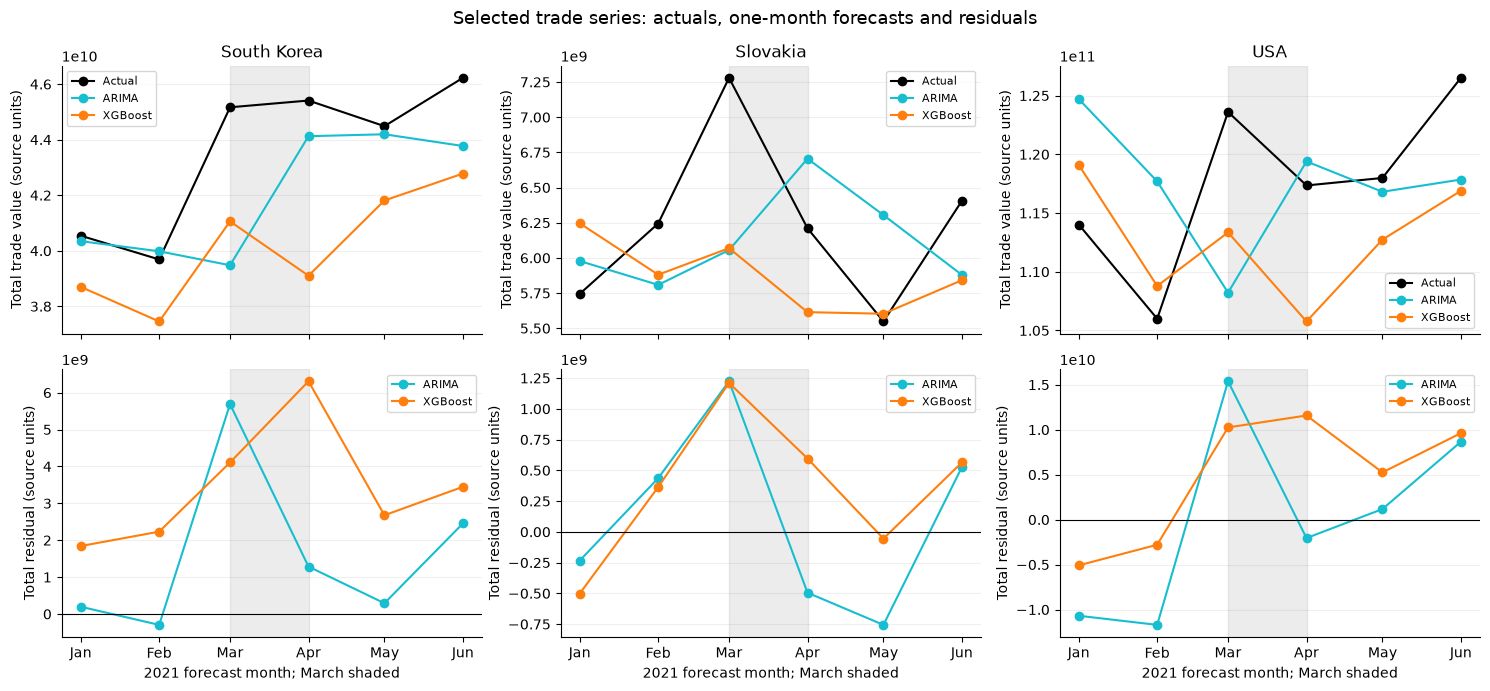

In [8]:
fig, axes = plt.subplots(
    2, len(COUNTRIES), figsize=(15, 7), sharex=True, squeeze=False
)
for column, country in enumerate(COUNTRIES):
    group = predictions.loc[predictions.Country.eq(country)]
    actual = group.loc[group.Model.eq("ARIMA")].groupby("Month")[TARGET].sum()
    axes[0, column].plot(
        actual.index, actual.values, marker="o", color="black", label="Actual"
    )
    for model in MODELS:
        totals = group.loc[group.Model.eq(model)].groupby("Month")[
            ["Prediction", "Residual"]
        ].sum()
        axes[0, column].plot(
            totals.index, totals.Prediction, marker="o",
            color=MODEL_COLORS[model], label=model,
        )
        axes[1, column].plot(
            totals.index, totals.Residual, marker="o",
            color=MODEL_COLORS[model], label=model,
        )
    axes[1, column].axhline(0, color="black", linewidth=0.8)
    for ax in axes[:, column]:
        ax.axvspan(
            EVENT_MONTH, EVENT_MONTH + pd.DateOffset(months=1),
            color="grey", alpha=0.15,
        )
        ax.legend(fontsize=8)
        ax.grid(axis="x", visible=False)
    axes[0, column].set_title(country)
    axes[0, column].set_ylabel("Total trade value (source units)")
    axes[1, column].set_ylabel("Total residual (source units)")
    axes[1, column].set_xticks(FORECAST_MONTHS)
    axes[1, column].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    axes[1, column].set_xlabel("2021 forecast month; March shaded")
fig.suptitle("Selected trade series: actuals, one-month forecasts and residuals", fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_forecast.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)


## 9. Monthly Error Trajectories

Compare monthly MAE, RMSE and sMAPE, with a common sMAPE scale across countries and country-specific scales for raw trade-value errors. Pre-event, event and post-event summaries are retained in the period table rather than a separate bar chart.

Lower errors indicate better accuracy, but a lower post-event error alone does not establish superior adaptation: pre-event accuracy, source coverage and changing trade conditions also matter.


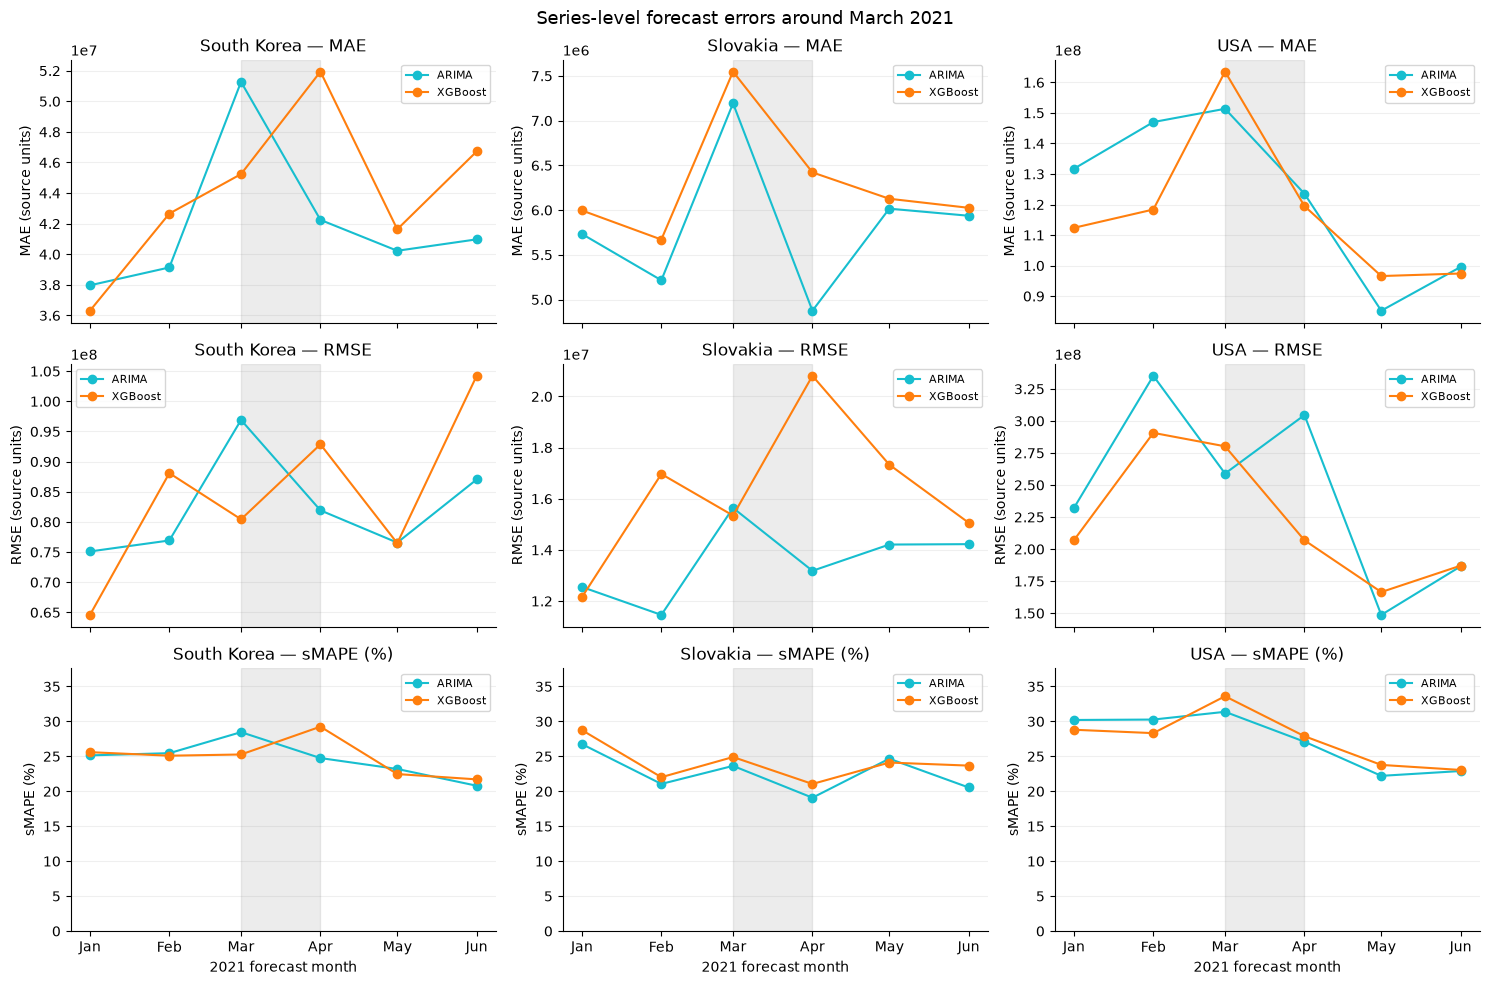

In [9]:
monthly_results["Month"] = pd.to_datetime(monthly_results["Forecast Month"])
fig, axes = plt.subplots(3, len(COUNTRIES), figsize=(15, 10), sharex=True, squeeze=False)
for row_index, metric in enumerate(["MAE", "RMSE", "sMAPE (%)"]):
    for column_index, country in enumerate(COUNTRIES):
        ax = axes[row_index, column_index]
        for model in MODELS:
            group = monthly_results.loc[
                monthly_results.Country.eq(country) & monthly_results.Model.eq(model)
            ].sort_values("Month")
            ax.plot(group.Month, group[metric], marker="o", color=MODEL_COLORS[model], label=model)
        ax.axvspan(EVENT_MONTH, EVENT_MONTH + pd.DateOffset(months=1), color="grey", alpha=0.15)
        ax.set_title(f"{country} — {metric}")
        ax.set_ylabel(metric if metric == "sMAPE (%)" else f"{metric} (source units)")
        ax.set_xticks(FORECAST_MONTHS)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        ax.grid(axis="x", visible=False)
        ax.legend(fontsize=8)
        if metric == "sMAPE (%)":
            ax.set_ylim(0, max(1.0, float(monthly_results[metric].max()) * 1.12))
        else:
            ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
for ax in axes[-1]:
    ax.set_xlabel("2021 forecast month")
fig.suptitle("Series-level forecast errors around March 2021", fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "monthly_errors.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)


## 10. Descriptive Findings and Limitations

The summaries identify which model has lower sMAPE in each window and how each model's errors change relative to the pre-event reference. They do not infer that Suez caused those errors or that a model anticipated the blockage.

This case provides limited evidence relevant to the broader shock-adaptation question: March predictions precede the unforeseen disruption, while April–June origins can respond to observed changes. Two pre-event months and three post-event months cannot establish a stable normal-error distribution, long-term recovery or general superiority of a model family.

The 200-series cap, two-model comparison and six-origin window keep repeated historical fitting feasible under the available computation; the 24-month minimum also reflects the short Korean history. These are deliberate scope restrictions rather than incorrect fitting logic, but the high-value sample is not representative and the short window cannot establish general shock adaptation. Reusing the selected 2026 XGBoost configuration avoids a separate historical search; despite chronological fitting, this remains retrospective model selection and must not be presented as a decision made with 2021 information alone. Missing route/exposure information, real-time publication vintages and suitable controls are data limitations that prevent causal attribution. Practical constraints explain these compromises without resolving their inferential consequences.


In [10]:
display(period_results[
    ["Country", "Model", "Period", "N Series", "N Months", "N Observations",
     "MAE", "RMSE", "sMAPE (%)", "sMAPE difference (pp)", "Naive fallbacks"]
])
for country in COUNTRIES:
    for period in ["Pre-event", "Event", "Post-event"]:
        group = period_results.loc[
            period_results.Country.eq(country) & period_results.Period.eq(period)
        ]
        best = group.loc[group["sMAPE (%)"].eq(group["sMAPE (%)"].min())]
        names = ", ".join(best.Model)
        print(
            f"{country}, {period}: lowest sMAPE {names} "
            f"({best['sMAPE (%)'].iloc[0]:.2f}%)."
        )
    for model in MODELS:
        post = period_results.loc[
            period_results.Country.eq(country) & period_results.Model.eq(model)
            & period_results.Period.eq("Post-event")
        ].iloc[0]
        print(
            f"{country}, {model}: post-event minus pre-event sMAPE "
            f"{post['sMAPE difference (pp)']:+.2f} percentage points; "
            f"{post['Naive fallbacks']} post-event naive fallbacks."
        )

print("\nAll Suez outputs are saved under:", OUTPUT_DIR)
for filename in [
    "monthly_results.csv", "period_results.csv",
    "actual_vs_forecast.png", "monthly_errors.png",
]:
    assert (OUTPUT_DIR / filename).is_file()
    print(filename)


,Country,Model,Period,N Series,N Months,N Observations,MAE,RMSE,sMAPE (%),sMAPE difference (pp),Naive fallbacks
2,Slovakia,ARIMA,Pre-event,200,2,400,5.474196e+06,1.201702e+07,23.901188,0.000000,22
0,Slovakia,ARIMA,Event,200,1,200,7.193018e+06,1.564230e+07,23.634439,-0.266749,14
1,Slovakia,ARIMA,Post-event,200,3,600,5.609322e+06,1.388129e+07,21.429777,-2.471411,25
5,Slovakia,XGBoost,Pre-event,200,2,400,5.833386e+06,1.475858e+07,25.384000,0.000000,0
3,Slovakia,XGBoost,Event,200,1,200,7.547744e+06,1.534428e+07,24.901546,-0.482454,0
4,Slovakia,XGBoost,Post-event,200,3,600,6.191136e+06,1.789181e+07,22.945262,-2.438738,0
8,South Korea,ARIMA,Pre-event,200,2,400,3.855386e+07,7.601939e+07,25.297110,0.000000,18
6,South Korea,ARIMA,Event,200,1,200,5.127042e+07,9.691139e+07,28.462547,3.165437,8
7,South Korea,ARIMA,Post-event,200,3,600,4.115034e+07,8.195492e+07,22.913566,-2.383545,20
11,South Korea,XGBoost,Pre-event,200,2,400,3.948435e+07,7.723557e+07,25.344879,0.000000,0


South Korea, Pre-event: lowest sMAPE ARIMA (25.30%).
South Korea, Event: lowest sMAPE XGBoost (25.27%).
South Korea, Post-event: lowest sMAPE ARIMA (22.91%).
South Korea, ARIMA: post-event minus pre-event sMAPE -2.38 percentage points; 20 post-event naive fallbacks.
South Korea, XGBoost: post-event minus pre-event sMAPE -0.87 percentage points; 0 post-event naive fallbacks.
Slovakia, Pre-event: lowest sMAPE ARIMA (23.90%).
Slovakia, Event: lowest sMAPE ARIMA (23.63%).
Slovakia, Post-event: lowest sMAPE ARIMA (21.43%).
Slovakia, ARIMA: post-event minus pre-event sMAPE -2.47 percentage points; 25 post-event naive fallbacks.
Slovakia, XGBoost: post-event minus pre-event sMAPE -2.44 percentage points; 0 post-event naive fallbacks.
USA, Pre-event: lowest sMAPE XGBoost (28.56%).
USA, Event: lowest sMAPE ARIMA (31.37%).
USA, Post-event: lowest sMAPE ARIMA (24.07%).
USA, ARIMA: post-event minus pre-event sMAPE -6.17 percentage points; 23 post-event naive fallbacks.
USA, XGBoost: post-event min

## Summary

The analysis compares ARIMA and XGBoost on a fixed preselected historical cohort using six genuine one-month-ahead forecast origins. Inputs are restricted to earlier trade observations, missing months remain zero, and unsuccessful ARIMA fits remain visible through recorded fallbacks.

Interpretation is conditional on retrospective XGBoost configuration selection, a high-value 200-series sample, short Korean history, changing source coverage, and the assumption that preceding-month trade is available at each origin. Historical publication dates and vintages, shipping routes, exposure measures and controls are unavailable. COVID-era developments, seasonality and other concurrent changes may also affect errors. Results are descriptive forecast-response evidence around the event, not a causal Suez estimate or a broad test of general adaptation.

## 11. RQ3 — Interpretation of Trade-Shock Response

**How do machine learning and classical time series models differ in their ability to capture and adapt to disruptive trade shocks?**

The Suez case provides no consistent evidence that the tested machine learning approach adapts better than the classical approach. ARIMA has lower pooled April–June sMAPE in all three countries and lower post-event MAE in all three, although USA XGBoost has lower post-event RMSE. Both procedures respond to updated observations, but neither consistently tracks every monthly change. These are comparative forecast-response findings around the event, not proof that either model identified or anticipated a Suez-specific shock.

**Numerical evidence and country differences**

The comparison uses 200 fixed series per country, selected using December 2020 and earlier information. Each model produces six successive one-month-ahead forecasts for January–June 2021, giving 1,200 forecasts per country-model combination and 7,200 overall. The pre-event period pools January–February (400 observations per combination), March contains 200, and April–June contains 600. Period RMSE is calculated by pooling squared errors rather than averaging monthly RMSE.

| Country | Model | Pre-event sMAPE (%) | March sMAPE (%) | Post-event sMAPE (%) | Post minus pre (pp) | Post-event MAE change (%) | Post-event RMSE change (%) |
|---|---|---:|---:|---:|---:|---:|---:|
| South Korea | ARIMA | 25.30 | 28.46 | 22.91 | -2.38 | +6.73 | +7.81 |
| South Korea | XGBoost | 25.34 | 25.27 | 24.47 | -0.87 | +18.44 | +18.98 |
| Slovakia | ARIMA | 23.90 | 23.63 | 21.43 | -2.47 | +2.47 | +15.51 |
| Slovakia | XGBoost | 25.38 | 24.90 | 22.95 | -2.44 | +6.13 | +21.23 |
| USA | ARIMA | 30.23 | 31.37 | 24.07 | -6.17 | -26.25 | -22.53 |
| USA | XGBoost | 28.56 | 33.60 | 24.90 | -3.66 | -9.43 | -25.67 |

Percentage changes compare each model with its own January–February reference; a larger reduction is not automatically evidence of faster adaptation because starting accuracy differs.

For **South Korea**, XGBoost is better in March on all three metrics: sMAPE is 25.27% versus ARIMA's 28.46%, with MAE of 45.24 million versus 51.27 million and RMSE of 80.44 million versus 96.91 million, in source units. Its sMAPE then rises to 29.25% in April before falling to 22.46% in May and 21.71% in June. ARIMA's post-event sMAPE is lower overall (22.91% versus 24.47%), as are its pooled MAE (41.15 million versus 46.76 million) and RMSE (81.95 million versus 91.90 million). The April XGBoost deterioration followed by improvement is compatible with delayed adjustment, but does not identify a delayed Suez effect. Neither model's post-event absolute-value errors return below its pre-event reference, despite lower sMAPE.

For **Slovakia**, ARIMA has lower sMAPE in all three periods. March MAE increases relative to each model's pre-event reference by 31.40% for ARIMA and 29.39% for XGBoost, even though sMAPE decreases slightly. Thus March does not show a common deterioration across error criteria. Post-event ARIMA MAE is 5.61 million versus XGBoost's 6.19 million, and RMSE is 13.88 million versus 17.89 million. ARIMA's monthly sMAPE falls to 19.08% in April, rises to 24.66% in May and falls again to 20.55% in June. This fluctuating path does not support a simple, steadily improving recovery narrative. Both models retain higher pooled post-event MAE and RMSE than before March.

For the **USA**, XGBoost is more accurate before the event on all three metrics, but its March sMAPE rises from a pre-event 28.56% to 33.60%. ARIMA rises more modestly from 30.23% to 31.37%. Post-event sMAPE favours ARIMA (24.07% versus 24.90%), as does MAE (102.78 million versus 104.50 million). RMSE instead favours XGBoost (187.55 million versus 223.36 million). Both procedures' post-event MAE, RMSE and sMAPE improve relative to their own pre-event reference. This indicates better subsequent forecast accuracy, without establishing that one procedure learned the disruption itself.

**Actual values, residuals and persistence**

In `actual_vs_forecast.png`, selected-cohort trade totals rise in March in all three countries; the data do not show a universal contemporaneous collapse. South Korean totals remain high in April, while Slovak and US totals fall from March to April and rise again by June. These are totals for the selected series, not complete national trade.

Both procedures underpredict the March aggregate in every country. With residuals defined as actual minus forecast, their March total residuals are positive. ARIMA forecasts increase in April after observing March, but overshoot actual totals in Slovakia and the USA. XGBoost continues to underpredict those April totals. This shows different responses to new observations rather than proof of successful shock recognition. South Korean XGBoost has positive aggregate residuals throughout the six months; persistent underprediction already present before March cannot be attributed solely to the event.

The figure `monthly_errors.png` shows that timing differs by model, country and metric: South Korean XGBoost sMAPE peaks in April, USA sMAPE peaks in March for both models, and Slovak sMAPE is highest in January for both. By May–June, both models' sMAPE is below their own pooled pre-event reference in every country. There is consequently no common persistent post-March proportional-error increase. Opposite errors can cancel in aggregate residuals, and lower proportional errors can coexist with higher trade-value errors, so both figures and all three metrics are needed.

**Plausible interpretation, assumptions and limitations**

ARIMA adapts through each series' updated history and refitted dynamics; XGBoost uses updated lagged and rolling features within a shared country model. Their different behaviour is consistent with these representations, but the experiment does not isolate architecture effects. March forecasts are formed before March observations and cannot use the unforeseen blockage. April–June forecasts can respond to earlier observed changes. Delayed errors are compatible with downstream effects, but without exposure measures and controls they cannot distinguish those effects from seasonality, COVID-era developments or other concurrent changes.

The two-model, six-origin design and 200-series cap make repeated fitting feasible under limited compute; the 24-month minimum reflects short Korean coverage. These are defensible scope choices, but the high-value sample is not representative and two pre-event months cannot establish normal error variability. XGBoost configurations are reused from 2026 to avoid another search: historical fitting is chronological, but selection is retrospective, so this is not a fully real-time 2021 experiment.

ARIMA uses 160 Naive fallbacks across 3,600 forecasts: 46 for South Korea, 61 for Slovakia and 53 for the USA (3.83%, 5.08% and 4.42%). Keeping them preserves matched cohorts, but means the reported procedure combines ARIMA and fallback forecasts. Five negative ARIMA forecasts also remain, whereas XGBoost predictions are constrained to be nonnegative. Missing trade observations are set to zero under the project assumption; changing extract coverage, particularly in early-2021 USA data, may affect the analysis. Preceding-month trade availability is assumed, and publication vintages and verified Suez-route exposure are unavailable. These limitations restrict causal and general adaptation claims.

**Main findings and answer**

- ARIMA provides stronger pooled post-event sMAPE and MAE across the three selected cohorts; USA XGBoost provides stronger post-event RMSE.
- XGBoost's March advantage in South Korea does not persist uniformly into April. Relative performance depends on the forecast origin and error criterion.
- Both procedures respond after new trade observations arrive, but neither demonstrates advance prediction of the event or reliable identification of its delayed effects.
- The evidence supports a conditional comparison of forecast response around one disruption, with no demonstrated general machine learning advantage. Lower subsequent errors show improved forecast accuracy, not proof of economic recovery or causal adaptation to Suez.
